In [1]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: NVIDIA L4


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Pet_Adoption_Final_Project"

folders = [
    "data",
    "features",
    "models",
    "figures"
]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_DIR, folder),
        exist_ok=True
    )

print("Project directory:", PROJECT_DIR)
print("Folders:", os.listdir(PROJECT_DIR))

Project directory: /content/drive/MyDrive/Pet_Adoption_Final_Project
Folders: ['data', 'features', 'models', 'figures']


In [7]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Paste your Kaggle API token: ")
print("Token saved for this session.")

Paste your Kaggle API token: ··········
Token saved for this session.


In [8]:
!pip install -q --upgrade kaggle

In [9]:
!kaggle competitions files -c petfinder-adoption-prediction

Next Page Token = CfDJ8CXkJvnxKG5Ktgac76JjV5GgSNtyYxKq_Fnn7A6mfo_SkCW-DKJjURRVHCJFNXoc_Qykh9bTOeG5xxsgTm0DGju3RQiUx_09gtaYXmkG08LFBIMX5XYSA71ee64-IIljpuHTZ1GxHYYIGs0H5cSR-jZoz_8
name                               size  creationDate                
---------------------------  ----------  --------------------------  
BreedLabels.csv                    6984  2019-12-11 22:09:28.558000  
ColorLabels.csv                      88  2019-12-11 22:09:28.070000  
PetFinder-BreedLabels.csv          6984  2019-12-11 22:09:28.061000  
PetFinder-ColorLabels.csv            88  2019-12-11 22:09:28.029000  
PetFinder-StateLabels.csv           285  2019-12-11 22:09:28.069000  
StateLabels.csv                     285  2019-12-11 22:09:28.077000  
breed_labels.csv                   6984  2019-12-11 22:09:28.097000  
color_labels.csv                     88  2019-12-11 22:09:28.049000  
state_labels.csv                    285  2019-12-11 22:09:28.064000  
test/sample_submission.csv        47684  2019-12-11 

In [20]:
TRAIN_DIR = f"{PROJECT_DIR}/data"

!kaggle competitions download \
    petfinder-adoption-prediction \
    -f train/train.csv \
    -p "$TRAIN_DIR"

100% 2.70M/2.70M [00:01<00:00, 1.81MB/s]



In [21]:
import os
import zipfile

zip_path = f"{PROJECT_DIR}/data/train/train.csv.zip"
extract_dir = f"{PROJECT_DIR}/data/train"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Files in train folder:")
print(os.listdir(extract_dir))

Files in train folder:
['train.csv.zip', 'train.csv']


In [22]:
import pandas as pd

train_path = f"{PROJECT_DIR}/data/train/train.csv"

df = pd.read_csv(train_path)

print("Shape:", df.shape)
display(df.head())

Shape: (14993, 24)


,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,...,Health,Quantity,Fee,State,RescuerID,VideoAmt,Description,PetID,PhotoAmt,AdoptionSpeed
0,2,Nibble,3,299,0,1,1,7,0,1,...,1,1,100,41326,8480853f516546f6cf33aa88cd76c379,0,Nibble is a 3+ month old ball of cuteness. He ...,86e1089a3,1.0,2
1,2,No Name Yet,1,265,0,1,1,2,0,2,...,1,1,0,41401,3082c7125d8fb66f7dd4bff4192c8b14,0,I just found it alone yesterday near my apartm...,6296e909a,2.0,0
2,1,Brisco,1,307,0,1,2,7,0,2,...,1,1,0,41326,fa90fa5b1ee11c86938398b60abc32cb,0,Their pregnant mother was dumped by her irresp...,3422e4906,7.0,3
3,1,Miko,4,307,0,2,1,2,0,2,...,1,1,150,41401,9238e4f44c71a75282e62f7136c6b240,0,"Good guard dog, very alert, active, obedience ...",5842f1ff5,8.0,2
4,1,Hunter,1,307,0,1,1,0,0,2,...,1,1,0,41326,95481e953f8aed9ec3d16fc4509537e8,0,This handsome yet cute boy is up for adoption....,850a43f90,3.0,2


In [23]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
missing = df.isnull().sum().sort_values(ascending=False)
print(missing[missing > 0])

Columns:
['Type', 'Name', 'Age', 'Breed1', 'Breed2', 'Gender', 'Color1', 'Color2', 'Color3', 'MaturitySize', 'FurLength', 'Vaccinated', 'Dewormed', 'Sterilized', 'Health', 'Quantity', 'Fee', 'State', 'RescuerID', 'VideoAmt', 'Description', 'PetID', 'PhotoAmt', 'AdoptionSpeed']

Data types:
Type               int64
Name              object
Age                int64
Breed1             int64
Breed2             int64
Gender             int64
Color1             int64
Color2             int64
Color3             int64
MaturitySize       int64
FurLength          int64
Vaccinated         int64
Dewormed           int64
Sterilized         int64
Health             int64
Quantity           int64
Fee                int64
State              int64
RescuerID         object
VideoAmt           int64
Description       object
PetID             object
PhotoAmt         float64
AdoptionSpeed      int64
dtype: object

Missing values:
Name           1265
Description      13
dtype: int64


In [24]:
print("AdoptionSpeed distribution:")
print(df["AdoptionSpeed"].value_counts().sort_index())

print("\nPercentage:")
print(
    (df["AdoptionSpeed"].value_counts(normalize=True)
     .sort_index() * 100)
    .round(2)
)

AdoptionSpeed distribution:
AdoptionSpeed
0     410
1    3090
2    4037
3    3259
4    4197
Name: count, dtype: int64

Percentage:
AdoptionSpeed
0     2.73
1    20.61
2    26.93
3    21.74
4    27.99
Name: proportion, dtype: float64


In [25]:
print("Total duplicated rows:", df.duplicated().sum())
print("Duplicated PetID:", df["PetID"].duplicated().sum())

print("\nUnique PetID:", df["PetID"].nunique())
print("Unique RescuerID:", df["RescuerID"].nunique())

print("\nMissing Description:", df["Description"].isna().sum())
print("Missing Name:", df["Name"].isna().sum())

# Description length
desc_length = df["Description"].fillna("").str.split().str.len()

print("\nDescription word count:")
print(desc_length.describe())

Total duplicated rows: 0
Duplicated PetID: 0

Unique PetID: 14993
Unique RescuerID: 5595

Missing Description: 13
Missing Name: 1265

Description word count:
count    14993.000000
mean        62.953578
std         69.298553
min          0.000000
25%         21.000000
50%         44.000000
75%         81.000000
max       1257.000000
Name: Description, dtype: float64


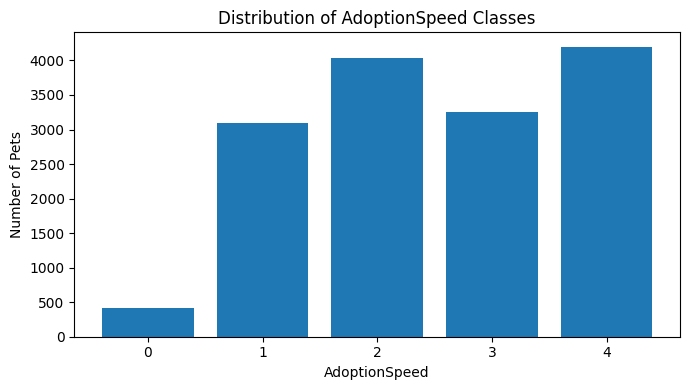

In [26]:
import matplotlib.pyplot as plt

class_counts = df["AdoptionSpeed"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(class_counts.index.astype(str), class_counts.values)

plt.xlabel("AdoptionSpeed")
plt.ylabel("Number of Pets")
plt.title("Distribution of AdoptionSpeed Classes")

plt.tight_layout()
plt.show()

In [27]:
tabular_cols = [
    "Type", "Age", "Breed1", "Breed2", "Gender",
    "Color1", "Color2", "Color3",
    "MaturitySize", "FurLength",
    "Vaccinated", "Dewormed", "Sterilized",
    "Health", "Quantity", "Fee", "State",
    "VideoAmt", "PhotoAmt"
]

summary = []

for col in tabular_cols:
    summary.append({
        "Feature": col,
        "Unique": df[col].nunique(),
        "Min": df[col].min(),
        "Max": df[col].max()
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

,Feature,Unique,Min,Max
0,Type,2,1.0,2.0
1,Age,106,0.0,255.0
2,Breed1,176,0.0,307.0
3,Breed2,135,0.0,307.0
4,Gender,3,1.0,3.0
5,Color1,7,1.0,7.0
6,Color2,7,0.0,7.0
7,Color3,6,0.0,7.0
8,MaturitySize,4,1.0,4.0
9,FurLength,3,1.0,3.0


In [28]:
rescuer_counts = df["RescuerID"].value_counts()

print("Pets per rescuer:")
print(rescuer_counts.describe())

print("\nTop 10 rescuers:")
print(rescuer_counts.head(10))

Pets per rescuer:
count    5595.000000
mean        2.679714
std        10.384820
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max       459.000000
Name: count, dtype: float64

Top 10 rescuers:
RescuerID
fa90fa5b1ee11c86938398b60abc32cb    459
aa66486163b6cbc25ea62a34b11c9b91    315
c00756f2bdd8fa88fc9f07a8309f7d5d    231
b53c34474d9e24574bcec6a3d3306a0d    228
ee2747ce26468ec44c7194e7d1d9dad9    156
95481e953f8aed9ec3d16fc4509537e8    134
b770bac0ca797cf1433c48a35d30c4cb    111
a042471e0f43f2cf707104a1a138a7df     95
fd970cc91d06d82eebf046340137b272     93
7ed6d84e2e6879245e55447aee39c328     85
Name: count, dtype: int64


In [29]:
numeric_cols = [
    "Age",
    "Quantity",
    "Fee",
    "VideoAmt",
    "PhotoAmt"
]

display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,14993.0,10.452078,18.155790,0.0,2.0,3.0,12.0,255.0
Quantity,14993.0,1.576069,1.472477,1.0,1.0,1.0,1.0,20.0
Fee,14993.0,21.259988,78.414548,0.0,0.0,0.0,0.0,3000.0
VideoAmt,14993.0,0.056760,0.346185,0.0,0.0,0.0,0.0,8.0
PhotoAmt,14993.0,3.889215,3.487810,0.0,2.0,3.0,5.0,30.0


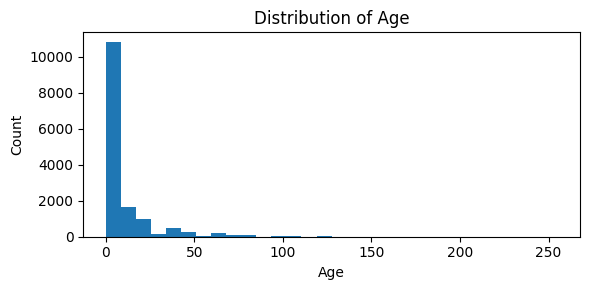

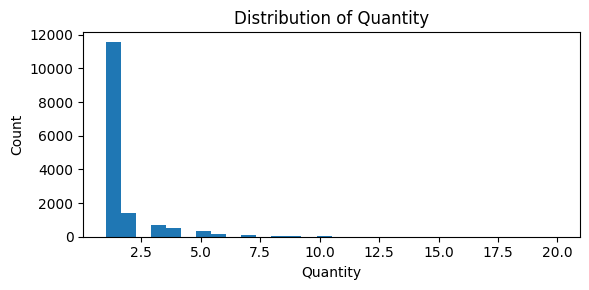

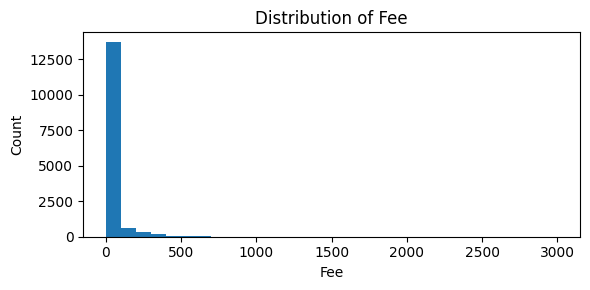

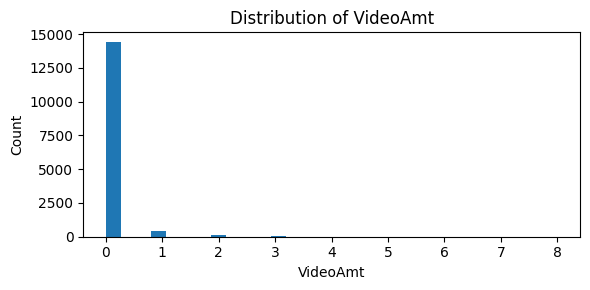

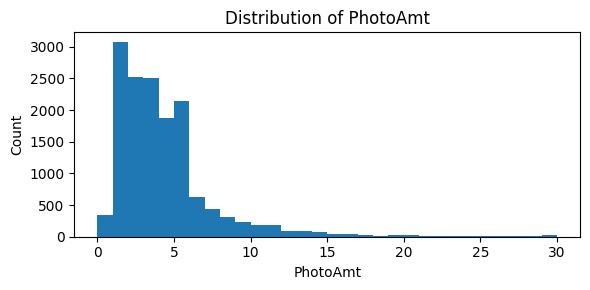

In [30]:
import matplotlib.pyplot as plt

for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    plt.hist(df[col].dropna(), bins=30)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

In [31]:
print("Age >= 100 months:", (df["Age"] >= 100).sum())
print("Age = 255:", (df["Age"] == 255).sum())

display(
    df.loc[df["Age"] >= 100,
           ["PetID", "Type", "Age", "Description", "AdoptionSpeed"]]
    .head(20)
)

Age >= 100 months: 85
Age = 255: 2


,PetID,Type,Age,Description,AdoptionSpeed
113,b84dad49f,1,120,I am posting this on my lecturer's behalf. She...,4
145,8e0d65b3e,1,120,2 males beagle & schnauzer for adoption. 10 & ...,1
513,f4f349714,2,132,"My name Chan Kok Wai, a 66 year old man who ha...",3
1057,e42dc215d,1,120,Found this silky terrier near tesco puchong. B...,0
1141,952501bdb,1,120,I rescued this poor puppy from the streets. Th...,3
1363,077001793,1,144,Teddie is a very good-natured dog. He is a ped...,3
1703,2e392586a,2,120,One of our rescued pets. Pinky needs a new hom...,4
1858,7f5e7cf4a,1,132,"This is Yuki, a mix Min Pinscher up for adopti...",2
1867,70335663e,1,135,I found a male schnauzer roaming around my are...,3
2263,da78c5792,2,120,Musy was a rescue cat I took in 3 years ago.Sh...,4


In [35]:
import os

LOCAL_DATA = "/content/petfinder_data"
os.makedirs(LOCAL_DATA, exist_ok=True)

!kaggle competitions download \
    petfinder-adoption-prediction \
    -p "$LOCAL_DATA"

100% 1.94G/1.94G [01:43<00:00, 20.1MB/s]



In [36]:
!du -sh /content/petfinder_data
!ls -lh /content/petfinder_data | head

2.0G	/content/petfinder_data
total 2.0G
-rw-r--r-- 1 root root 2.0G Dec 11  2019 petfinder-adoption-prediction.zip


In [40]:
ZIP_PATH = "/content/petfinder_data/petfinder-adoption-prediction.zip"
EXTRACT_DIR = "/content/petfinder_data/extracted"

import os
os.makedirs(EXTRACT_DIR, exist_ok=True)

!unzip -q "$ZIP_PATH" -d "$EXTRACT_DIR"

print("Extraction finished.")

replace /content/petfinder_data/extracted/BreedLabels.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
Extraction finished.


In [41]:
!find /content/petfinder_data/extracted -maxdepth 2 -type d | head -30

/content/petfinder_data/extracted
/content/petfinder_data/extracted/train_sentiment
/content/petfinder_data/extracted/train_metadata
/content/petfinder_data/extracted/test
/content/petfinder_data/extracted/test_images
/content/petfinder_data/extracted/train_images
/content/petfinder_data/extracted/test_sentiment
/content/petfinder_data/extracted/train
/content/petfinder_data/extracted/test_metadata


In [42]:
!find /content/petfinder_data/extracted -maxdepth 2 -type f | head -30

/content/petfinder_data/extracted/train_sentiment/0008c5398.json
/content/petfinder_data/extracted/train_sentiment/000a290e4.json
/content/petfinder_data/extracted/train_sentiment/000fb9572.json
/content/petfinder_data/extracted/train_sentiment/0011d7c25.json
/content/petfinder_data/extracted/train_sentiment/00156db4a.json
/content/petfinder_data/extracted/train_sentiment/001a1aaad.json
/content/petfinder_data/extracted/train_sentiment/001b1507c.json
/content/petfinder_data/extracted/train_sentiment/002230dea.json
/content/petfinder_data/extracted/train_sentiment/002278114.json
/content/petfinder_data/extracted/train_sentiment/0038234c6.json
/content/petfinder_data/extracted/train_sentiment/0038c9343.json
/content/petfinder_data/extracted/train_sentiment/003dd2e26.json
/content/petfinder_data/extracted/train_sentiment/0045ed62a.json
/content/petfinder_data/extracted/train_sentiment/004709939.json
/content/petfinder_data/extracted/train_sentiment/004a26127.json
/content/petfinder_data/e

In [43]:
import os
import glob

TRAIN_IMAGE_DIR = "/content/petfinder_data/extracted/train_images"

image_files = glob.glob(os.path.join(TRAIN_IMAGE_DIR, "*.jpg"))

print("Total training images:", len(image_files))
print("First 5 image files:")
for f in image_files[:5]:
    print(os.path.basename(f))

Total training images: 58311
First 5 image files:
c670993fc-11.jpg
4b6c04393-1.jpg
e456bf863-1.jpg
828f0e616-3.jpg
d5cbed556-1.jpg


In [44]:
# Example:
# abc123-1.jpg -> abc123

image_pet_ids = [
    os.path.basename(f).rsplit("-", 1)[0]
    for f in image_files
]

unique_image_pet_ids = set(image_pet_ids)

print("Unique pets with images:", len(unique_image_pet_ids))
print("Total pets in train.csv:", df["PetID"].nunique())

pets_without_images = ~df["PetID"].isin(unique_image_pet_ids)

print("Pets without images:", pets_without_images.sum())
print(
    "Percentage with at least one image:",
    round((1 - pets_without_images.mean()) * 100, 2),
    "%"
)

Unique pets with images: 14652
Total pets in train.csv: 14993
Pets without images: 341
Percentage with at least one image: 97.73 %


In [45]:
from collections import Counter

image_count_by_pet = Counter(image_pet_ids)

df["ActualPhotoCount"] = df["PetID"].map(image_count_by_pet).fillna(0).astype(int)

print("Actual image count per pet:")
print(df["ActualPhotoCount"].describe())

print("\nPhotoAmt vs actual images:")
display(
    df[["PetID", "PhotoAmt", "ActualPhotoCount"]].head(20)
)

print(
    "\nNumber of mismatches:",
    (df["PhotoAmt"] != df["ActualPhotoCount"]).sum()
)

Actual image count per pet:
count    14993.000000
mean         3.889215
std          3.487810
min          0.000000
25%          2.000000
50%          3.000000
75%          5.000000
max         30.000000
Name: ActualPhotoCount, dtype: float64

PhotoAmt vs actual images:


,PetID,PhotoAmt,ActualPhotoCount
0,86e1089a3,1.0,1
1,6296e909a,2.0,2
2,3422e4906,7.0,7
3,5842f1ff5,8.0,8
4,850a43f90,3.0,3
5,d24c30b4b,2.0,2
6,1caa6fcdb,3.0,3
7,97aa9eeac,9.0,9
8,c06d167ca,6.0,6
9,7a0942d61,2.0,2



Number of mismatches: 0


In [46]:
has_image = df["PetID"].isin(unique_image_pet_ids)

has_text = (
    df["Description"].notna()
    & df["Description"].str.strip().ne("")
)

complete_mask = has_image & has_text

print("Total pets:", len(df))
print("Pets with image:", has_image.sum())
print("Pets with description:", has_text.sum())
print("Pets with both image and description:", complete_mask.sum())

print(
    "Complete multimodal percentage:",
    round(complete_mask.mean() * 100, 2),
    "%"
)

Total pets: 14993
Pets with image: 14652
Pets with description: 14980
Pets with both image and description: 14640
Complete multimodal percentage: 97.65 %


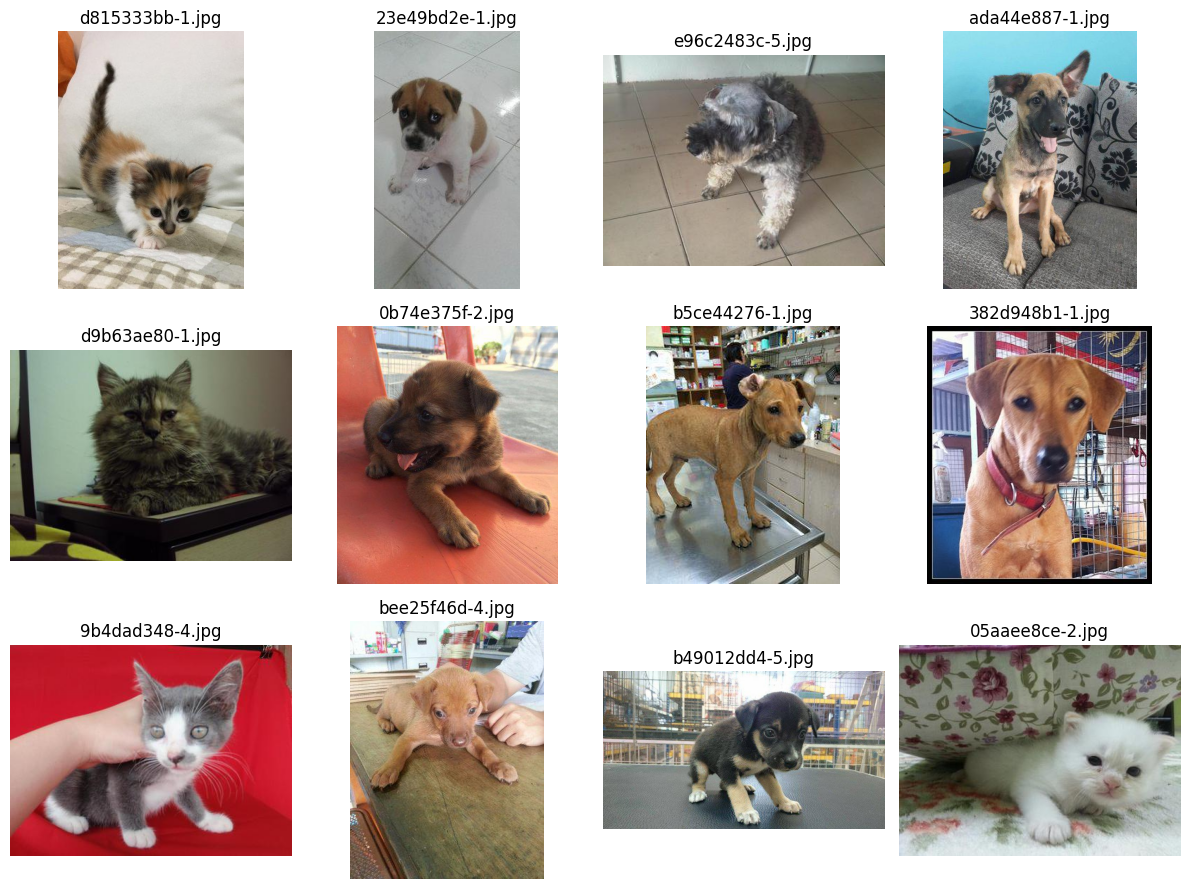

In [47]:
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

sample_files = random.sample(image_files, 12)

plt.figure(figsize=(12, 9))

for i, path in enumerate(sample_files):
    img = Image.open(path).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(os.path.basename(path))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [48]:
from PIL import Image
from collections import Counter

sizes = []
corrupted = []

for path in image_files:
    try:
        with Image.open(path) as img:
            sizes.append(img.size)
    except Exception:
        corrupted.append(path)

size_counts = Counter(sizes)

print("Corrupted images:", len(corrupted))
print("Unique image sizes:", len(size_counts))

print("\nMost common image sizes:")
for size, count in size_counts.most_common(10):
    print(size, count)

Corrupted images: 0
Unique image sizes: 2389

Most common image sizes:
(400, 300) 12816
(360, 480) 7145
(300, 400) 6086
(640, 480) 4163
(270, 480) 2722
(640, 360) 2006
(640, 640) 1228
(203, 360) 1047
(400, 267) 1007
(400, 225) 906


In [49]:
aspect_ratios = [w / h for w, h in sizes]

print("Aspect ratio summary:")
print("Min:", round(min(aspect_ratios), 2))
print("Max:", round(max(aspect_ratios), 2))
print("Mean:", round(sum(aspect_ratios) / len(aspect_ratios), 2))

Aspect ratio summary:
Min: 0.24
Max: 4.94
Mean: 1.07


In [50]:
import random
import numpy as np
import cv2

random.seed(42)

quality_sample = random.sample(image_files, 2000)

brightness_values = []
sharpness_values = []

for path in quality_sample:
    img = cv2.imread(path)

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Mean pixel intensity
    brightness = gray.mean()

    # Laplacian variance: higher = sharper
    sharpness = cv2.Laplacian(gray, cv2.CV_64F).var()

    brightness_values.append(brightness)
    sharpness_values.append(sharpness)

print("Brightness")
print("Mean:", round(np.mean(brightness_values), 2))
print("Min:", round(np.min(brightness_values), 2))
print("Max:", round(np.max(brightness_values), 2))

print("\nSharpness")
print("Mean:", round(np.mean(sharpness_values), 2))
print("Min:", round(np.min(sharpness_values), 2))
print("Max:", round(np.max(sharpness_values), 2))

Brightness
Mean: 121.2
Min: 17.63
Max: 233.7

Sharpness
Mean: 1104.49
Min: 13.96
Max: 27061.4


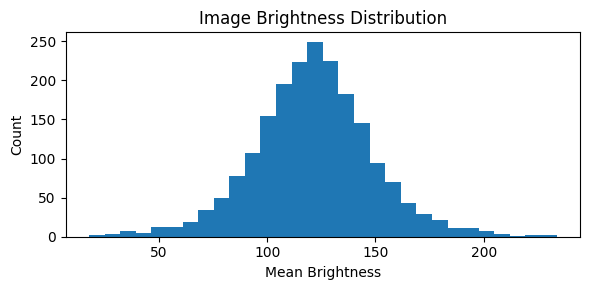

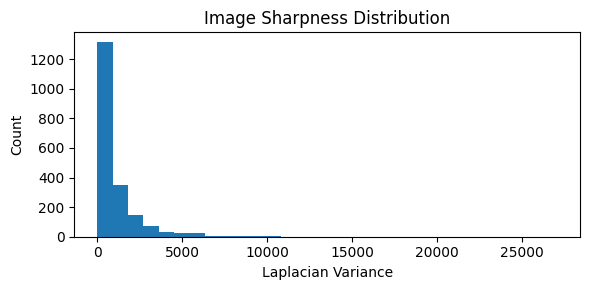

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))
plt.hist(brightness_values, bins=30)
plt.xlabel("Mean Brightness")
plt.ylabel("Count")
plt.title("Image Brightness Distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 3))
plt.hist(sharpness_values, bins=30)
plt.xlabel("Laplacian Variance")
plt.ylabel("Count")
plt.title("Image Sharpness Distribution")
plt.tight_layout()
plt.show()

In [52]:
df_model = df.loc[complete_mask].copy().reset_index(drop=True)

print("Samples used for modelling:", len(df_model))
print("Target distribution:")
print(df_model["AdoptionSpeed"].value_counts().sort_index())

Samples used for modelling: 14640
Target distribution:
AdoptionSpeed
0     386
1    3054
2    3996
3    3224
4    3980
Name: count, dtype: int64


In [53]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights = ResNet18_Weights.DEFAULT

resnet = resnet18(weights=weights)

# Remove final classification layer
resnet.fc = nn.Identity()

resnet = resnet.to(device)
resnet.eval()

image_transform = weights.transforms()

print("Device:", device)
print("ResNet18 ready.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 189MB/s]


Device: cuda
ResNet18 ready.


In [54]:
from PIL import Image

test_path = image_files[0]

img = Image.open(test_path).convert("RGB")
x = image_transform(img).unsqueeze(0).to(device)

with torch.no_grad():
    feature = resnet(x)

print("Image:", os.path.basename(test_path))
print("Input tensor shape:", x.shape)
print("Feature shape:", feature.shape)

Image: c670993fc-11.jpg
Input tensor shape: torch.Size([1, 3, 224, 224])
Feature shape: torch.Size([1, 512])


In [57]:
from torch.utils.data import Dataset, DataLoader

class PetImageDataset(Dataset):
    def __init__(self, image_paths, transform):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        path = self.image_paths[idx]

        img = Image.open(path).convert("RGB")
        img = self.transform(img)

        pet_id = os.path.basename(path).rsplit("-", 1)[0]

        return img, pet_id

model_pet_ids = set(df_model["PetID"])

model_image_files = [
    f for f in image_files
    if os.path.basename(f).rsplit("-", 1)[0] in model_pet_ids
]

print("Images used for modelling:", len(model_image_files))
print("Pets used for modelling:", len(model_pet_ids))

Images used for modelling: 58281
Pets used for modelling: 14640


In [58]:
image_dataset = PetImageDataset(
    model_image_files,
    image_transform
)

image_loader = DataLoader(
    image_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

print("Number of batches:", len(image_loader))

Number of batches: 456


In [59]:
images, pet_ids = next(iter(image_loader))

print("Batch image shape:", images.shape)
print("Number of PetIDs:", len(pet_ids))
print("First 5 PetIDs:", pet_ids[:5])

images = images.to(device)

with torch.no_grad():
    features = resnet(images)

print("Batch feature shape:", features.shape)

Batch image shape: torch.Size([128, 3, 224, 224])
Number of PetIDs: 128
First 5 PetIDs: ('c670993fc', '4b6c04393', 'e456bf863', '828f0e616', 'd5cbed556')
Batch feature shape: torch.Size([128, 512])


In [60]:
from collections import defaultdict
from tqdm.auto import tqdm
import numpy as np
import torch

# Store sum of image features and image count for each pet
feature_sums = defaultdict(lambda: np.zeros(512, dtype=np.float32))
feature_counts = defaultdict(int)

resnet.eval()

with torch.no_grad():
    for images, pet_ids in tqdm(image_loader, desc="Extracting image features"):

        images = images.to(device, non_blocking=True)

        batch_features = resnet(images)
        batch_features = batch_features.cpu().numpy()

        for pet_id, feat in zip(pet_ids, batch_features):
            feature_sums[pet_id] += feat
            feature_counts[pet_id] += 1

print("Feature extraction finished.")
print("Pets with extracted features:", len(feature_sums))

Extracting image features:   0%|          | 0/456 [00:00<?, ?it/s]

Feature extraction finished.
Pets with extracted features: 14640


In [61]:
image_features = []

for pet_id in df_model["PetID"]:
    mean_feature = feature_sums[pet_id] / feature_counts[pet_id]
    image_features.append(mean_feature)

image_features = np.vstack(image_features).astype(np.float32)

print("Final image feature shape:", image_features.shape)
print("NaN values:", np.isnan(image_features).sum())
print("Infinite values:", np.isinf(image_features).sum())

Final image feature shape: (14640, 512)
NaN values: 0
Infinite values: 0


In [62]:
FEATURE_DIR = f"{PROJECT_DIR}/features"

np.save(
    f"{FEATURE_DIR}/image_features_resnet18.npy",
    image_features
)

df_model[["PetID"]].to_csv(
    f"{FEATURE_DIR}/model_pet_ids.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


In [63]:
loaded_features = np.load(
    f"{FEATURE_DIR}/image_features_resnet18.npy"
)

print("Saved feature shape:", loaded_features.shape)

Saved feature shape: (14640, 512)


In [64]:
from transformers import AutoTokenizer, AutoModel
import torch

TEXT_MODEL_NAME = "bert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL_NAME)
text_model = AutoModel.from_pretrained(TEXT_MODEL_NAME)

text_model = text_model.to(device)
text_model.eval()

print("Text model:", TEXT_MODEL_NAME)
print("Device:", device)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Text model: bert-base-multilingual-cased
Device: cuda


In [65]:
texts = df_model["Description"].fillna("").astype(str).tolist()

token_lengths = []

for text in texts:
    tokens = tokenizer(
        text,
        add_special_tokens=True,
        truncation=False
    )

    token_lengths.append(len(tokens["input_ids"]))

import numpy as np

print("Token length summary:")
print("Mean:", round(np.mean(token_lengths), 2))
print("Median:", round(np.median(token_lengths), 2))
print("90th percentile:", round(np.percentile(token_lengths, 90), 2))
print("95th percentile:", round(np.percentile(token_lengths, 95), 2))
print("99th percentile:", round(np.percentile(token_lengths, 99), 2))
print("Max:", max(token_lengths))

print("\nOver 128:", sum(x > 128 for x in token_lengths))
print("Over 256:", sum(x > 256 for x in token_lengths))
print("Over 512:", sum(x > 512 for x in token_lengths))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (550 > 512). Running this sequence through the model will result in indexing errors


Token length summary:
Mean: 93.45
Median: 66.0
90th percentile: 194.0
95th percentile: 269.0
99th percentile: 503.0
Max: 1658

Over 128: 3143
Over 256: 808
Over 512: 137


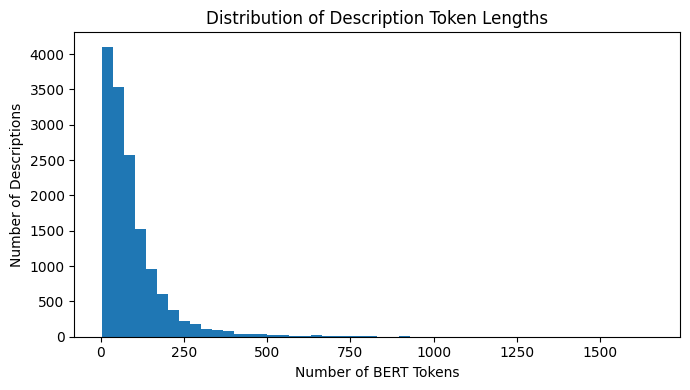

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.hist(token_lengths, bins=50)

plt.xlabel("Number of BERT Tokens")
plt.ylabel("Number of Descriptions")
plt.title("Distribution of Description Token Lengths")

plt.tight_layout()
plt.show()

In [67]:
MAX_LENGTH = 256

sample_texts = df_model["Description"].iloc[:8].tolist()

encoded = tokenizer(
    sample_texts,
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

encoded = {
    k: v.to(device)
    for k, v in encoded.items()
}

with torch.no_grad():
    outputs = text_model(**encoded)

last_hidden = outputs.last_hidden_state

print("Last hidden shape:", last_hidden.shape)

Last hidden shape: torch.Size([8, 105, 768])


In [68]:
attention_mask = encoded["attention_mask"]

mask = attention_mask.unsqueeze(-1).expand(last_hidden.size()).float()

sum_embeddings = torch.sum(last_hidden * mask, dim=1)
sum_mask = torch.clamp(mask.sum(dim=1), min=1e-9)

text_features_test = sum_embeddings / sum_mask

print("Pooled feature shape:", text_features_test.shape)

Pooled feature shape: torch.Size([8, 768])


In [69]:
 from torch.utils.data import Dataset, DataLoader

class PetTextDataset(Dataset):
    def __init__(self, texts):
        self.texts = texts

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx]


texts = df_model["Description"].astype(str).tolist()

text_dataset = PetTextDataset(texts)

text_loader = DataLoader(
    text_dataset,
    batch_size=64,
    shuffle=False
)

print("Number of texts:", len(text_dataset))
print("Number of batches:", len(text_loader))

Number of texts: 14640
Number of batches: 229


In [70]:
all_text_features = []

text_model.eval()

with torch.no_grad():
    for batch_texts in tqdm(text_loader, desc="Extracting text features"):

        encoded = tokenizer(
            list(batch_texts),
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        encoded = {
            k: v.to(device)
            for k, v in encoded.items()
        }

        outputs = text_model(**encoded)

        hidden = outputs.last_hidden_state
        attention_mask = encoded["attention_mask"]

        mask = attention_mask.unsqueeze(-1).expand(hidden.size()).float()

        summed = torch.sum(hidden * mask, dim=1)
        counts = torch.clamp(mask.sum(dim=1), min=1e-9)

        pooled = summed / counts

        all_text_features.append(
            pooled.cpu().numpy()
        )

Extracting text features:   0%|          | 0/229 [00:00<?, ?it/s]

In [71]:
text_features = np.vstack(all_text_features).astype(np.float32)

print("Text feature shape:", text_features.shape)
print("NaN values:", np.isnan(text_features).sum())
print("Infinite values:", np.isinf(text_features).sum())

Text feature shape: (14640, 768)
NaN values: 0
Infinite values: 0


In [72]:
np.save(
    f"{FEATURE_DIR}/text_features_mbert.npy",
    text_features
)

print("Text features saved.")

Text features saved.


In [73]:
loaded_text = np.load(
    f"{FEATURE_DIR}/text_features_mbert.npy"
)

print("Saved text feature shape:", loaded_text.shape)

Saved text feature shape: (14640, 768)


In [74]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

X_dummy = np.zeros(len(df_model))
y = df_model["AdoptionSpeed"].to_numpy()
groups = df_model["RescuerID"].to_numpy()

# First: make about 10% test set
sgkf_test = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

trainval_idx, test_idx = next(
    sgkf_test.split(X_dummy, y, groups)
)

# Then split remaining data into train + validation
y_trainval = y[trainval_idx]
groups_trainval = groups[trainval_idx]

sgkf_val = StratifiedGroupKFold(
    n_splits=9,
    shuffle=True,
    random_state=42
)

train_sub_idx, val_sub_idx = next(
    sgkf_val.split(
        np.zeros(len(trainval_idx)),
        y_trainval,
        groups_trainval
    )
)

train_idx = trainval_idx[train_sub_idx]
val_idx = trainval_idx[val_sub_idx]

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 11653
Validation: 1507
Test: 1480


In [75]:
import pandas as pd

def show_distribution(name, indices):
    counts = pd.Series(y[indices]).value_counts().sort_index()
    percentages = (
        pd.Series(y[indices])
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)

    print(f"\n{name}")
    print(pd.DataFrame({
        "Count": counts,
        "Percentage": percentages
    }))

show_distribution("Train", train_idx)
show_distribution("Validation", val_idx)
show_distribution("Test", test_idx)


Train
   Count  Percentage
0    326        2.80
1   2429       20.84
2   3180       27.29
3   2618       22.47
4   3100       26.60

Validation
   Count  Percentage
0     32        2.12
1    301       19.97
2    368       24.42
3    297       19.71
4    509       33.78

Test
   Count  Percentage
0     28        1.89
1    324       21.89
2    448       30.27
3    309       20.88
4    371       25.07


In [76]:
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

print("Train-Val overlap:", len(train_groups & val_groups))
print("Train-Test overlap:", len(train_groups & test_groups))
print("Val-Test overlap:", len(val_groups & test_groups))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [77]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd

y = df_model["AdoptionSpeed"].to_numpy()
groups = df_model["RescuerID"].to_numpy()

global_dist = (
    pd.Series(y)
    .value_counts(normalize=True)
    .sort_index()
    .reindex(range(5), fill_value=0)
    .to_numpy()
)

def distribution_difference(indices):
    dist = (
        pd.Series(y[indices])
        .value_counts(normalize=True)
        .sort_index()
        .reindex(range(5), fill_value=0)
        .to_numpy()
    )
    return np.abs(dist - global_dist).sum()



sgkf_test = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

test_candidates = []

for trainval_idx, test_idx in sgkf_test.split(
    np.zeros(len(y)),
    y,
    groups
):
    score = distribution_difference(test_idx)

    test_candidates.append(
        (score, trainval_idx, test_idx)
    )

_, trainval_idx, test_idx = min(
    test_candidates,
    key=lambda x: x[0]
)


y_trainval = y[trainval_idx]
groups_trainval = groups[trainval_idx]

sgkf_val = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

val_candidates = []

for train_sub, val_sub in sgkf_val.split(
    np.zeros(len(trainval_idx)),
    y_trainval,
    groups_trainval
):

    candidate_val_idx = trainval_idx[val_sub]

    score = distribution_difference(candidate_val_idx)

    val_candidates.append(
        (score, train_sub, val_sub)
    )

_, train_sub_idx, val_sub_idx = min(
    val_candidates,
    key=lambda x: x[0]
)

train_idx = trainval_idx[train_sub_idx]
val_idx = trainval_idx[val_sub_idx]


print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 10938
Validation: 1754
Test: 1948


In [78]:
def show_distribution(name, indices):
    counts = pd.Series(y[indices]).value_counts().sort_index()

    percentages = (
        pd.Series(y[indices])
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)

    print(f"\n{name}")

    print(
        pd.DataFrame({
            "Count": counts,
            "Percentage": percentages
        })
    )


show_distribution("Train", train_idx)
show_distribution("Validation", val_idx)
show_distribution("Test", test_idx)


Train
   Count  Percentage
0    297        2.72
1   2273       20.78
2   3005       27.47
3   2466       22.55
4   2897       26.49

Validation
   Count  Percentage
0     42        2.39
1    366       20.87
2    458       26.11
3    374       21.32
4    514       29.30

Test
   Count  Percentage
0     47        2.41
1    415       21.30
2    533       27.36
3    384       19.71
4    569       29.21


In [79]:
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

print(
    "Train-Val overlap:",
    len(train_groups & val_groups)
)

print(
    "Train-Test overlap:",
    len(train_groups & test_groups)
)

print(
    "Val-Test overlap:",
    len(val_groups & test_groups)
)

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [80]:
SPLIT_DIR = f"{PROJECT_DIR}/features"

np.save(f"{SPLIT_DIR}/train_idx.npy", train_idx)
np.save(f"{SPLIT_DIR}/val_idx.npy", val_idx)
np.save(f"{SPLIT_DIR}/test_idx.npy", test_idx)

print("Split indices saved.")

Split indices saved.


In [81]:
categorical_cols = [
    "Type",
    "Breed1",
    "Breed2",
    "Gender",
    "Color1",
    "Color2",
    "Color3",
    "MaturitySize",
    "FurLength",
    "Vaccinated",
    "Dewormed",
    "Sterilized",
    "Health",
    "State"
]

numeric_cols = [
    "Age",
    "Quantity",
    "Fee",
    "VideoAmt",
    "PhotoAmt"
]

In [82]:
tabular_cols = categorical_cols + numeric_cols

X_tab = df_model[tabular_cols]

X_tab_train = X_tab.iloc[train_idx]
X_tab_val = X_tab.iloc[val_idx]
X_tab_test = X_tab.iloc[test_idx]

print("Train:", X_tab_train.shape)
print("Validation:", X_tab_val.shape)
print("Test:", X_tab_test.shape)

Train: (10938, 19)
Validation: (1754, 19)
Test: (1948, 19)


In [84]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

tabular_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_cols
        )
    ]
)

X_tab_train_processed = tabular_preprocessor.fit_transform(
    X_tab_train
)

X_tab_val_processed = tabular_preprocessor.transform(
    X_tab_val
)

X_tab_test_processed = tabular_preprocessor.transform(
    X_tab_test
)

In [85]:
print("Train tabular shape:", X_tab_train_processed.shape)
print("Validation tabular shape:", X_tab_val_processed.shape)
print("Test tabular shape:", X_tab_test_processed.shape)

print(
    "NaN:",
    np.isnan(X_tab_train_processed).sum()
)

print(
    "Inf:",
    np.isinf(X_tab_train_processed).sum()
)

Train tabular shape: (10938, 347)
Validation tabular shape: (1754, 347)
Test tabular shape: (1948, 347)
NaN: 0
Inf: 0


In [86]:
import joblib
import numpy as np

np.save(
    f"{FEATURE_DIR}/tabular_train.npy",
    X_tab_train_processed.astype(np.float32)
)

np.save(
    f"{FEATURE_DIR}/tabular_val.npy",
    X_tab_val_processed.astype(np.float32)
)

np.save(
    f"{FEATURE_DIR}/tabular_test.npy",
    X_tab_test_processed.astype(np.float32)
)

joblib.dump(
    tabular_preprocessor,
    f"{FEATURE_DIR}/tabular_preprocessor.joblib"
)

print("Tabular features and preprocessor saved.")

Tabular features and preprocessor saved.


In [87]:
X_img_train = image_features[train_idx]
X_img_val = image_features[val_idx]
X_img_test = image_features[test_idx]

X_text_train = text_features[train_idx]
X_text_val = text_features[val_idx]
X_text_test = text_features[test_idx]

y = df_model["AdoptionSpeed"].to_numpy()

y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]
print("IMAGE")
print(X_img_train.shape, X_img_val.shape, X_img_test.shape)

print("\nTEXT")
print(X_text_train.shape, X_text_val.shape, X_text_test.shape)

print("\nTABULAR")
print(
    X_tab_train_processed.shape,
    X_tab_val_processed.shape,
    X_tab_test_processed.shape
)

print("\nTARGET")
print(y_train.shape, y_val.shape, y_test.shape)

IMAGE
(10938, 512) (1754, 512) (1948, 512)

TEXT
(10938, 768) (1754, 768) (1948, 768)

TABULAR
(10938, 347) (1754, 347) (1948, 347)

TARGET
(10938,) (1754,) (1948,)


In [88]:
np.save(f"{FEATURE_DIR}/train_idx.npy", train_idx)
np.save(f"{FEATURE_DIR}/val_idx.npy", val_idx)
np.save(f"{FEATURE_DIR}/test_idx.npy", test_idx)

print("Final split indices saved.")

Final split indices saved.


In [89]:
# Image
np.save(f"{FEATURE_DIR}/image_train.npy", X_img_train)
np.save(f"{FEATURE_DIR}/image_val.npy", X_img_val)
np.save(f"{FEATURE_DIR}/image_test.npy", X_img_test)

# Text
np.save(f"{FEATURE_DIR}/text_train.npy", X_text_train)
np.save(f"{FEATURE_DIR}/text_val.npy", X_text_val)
np.save(f"{FEATURE_DIR}/text_test.npy", X_text_test)

# Tabular
np.save(
    f"{FEATURE_DIR}/tabular_train.npy",
    X_tab_train_processed.astype(np.float32)
)

np.save(
    f"{FEATURE_DIR}/tabular_val.npy",
    X_tab_val_processed.astype(np.float32)
)

np.save(
    f"{FEATURE_DIR}/tabular_test.npy",
    X_tab_test_processed.astype(np.float32)
)

# Target
np.save(f"{FEATURE_DIR}/y_train.npy", y_train)
np.save(f"{FEATURE_DIR}/y_val.npy", y_val)
np.save(f"{FEATURE_DIR}/y_test.npy", y_test)

print("All modality splits saved.")

All modality splits saved.


In [90]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score
)

In [91]:
image_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    tree_method="hist"
)

In [92]:
image_model.fit(
    X_img_train,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [93]:
image_train_pred = image_model.predict(X_img_train)
image_val_pred = image_model.predict(X_img_val)

print("Image-only baseline")

print("\nTrain")
print(
    "Macro F1:",
    round(f1_score(
        y_train,
        image_train_pred,
        average="macro"
    ), 4)
)
print(
    "Weighted F1:",
    round(f1_score(
        y_train,
        image_train_pred,
        average="weighted"
    ), 4)
)

print("\nValidation")
print(
    "Macro F1:",
    round(f1_score(
        y_val,
        image_val_pred,
        average="macro"
    ), 4)
)
print(
    "Weighted F1:",
    round(f1_score(
        y_val,
        image_val_pred,
        average="weighted"
    ), 4)
)

print(
    "QWK:",
    round(
        cohen_kappa_score(
            y_val,
            image_val_pred,
            weights="quadratic"
        ),
        4
    )
)

Image-only baseline

Train
Macro F1: 0.9785
Weighted F1: 0.9744

Validation
Macro F1: 0.2602
Weighted F1: 0.3297
QWK: 0.2384


In [94]:
text_model_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    tree_method="hist"
)

text_model_xgb.fit(
    X_text_train,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [95]:
text_train_pred = text_model_xgb.predict(X_text_train)
text_val_pred = text_model_xgb.predict(X_text_val)

print("Text-only baseline")

print("\nTrain")
print(
    "Macro F1:",
    round(f1_score(
        y_train,
        text_train_pred,
        average="macro"
    ), 4)
)

print(
    "Weighted F1:",
    round(f1_score(
        y_train,
        text_train_pred,
        average="weighted"
    ), 4)
)

print("\nValidation")
print(
    "Macro F1:",
    round(f1_score(
        y_val,
        text_val_pred,
        average="macro"
    ), 4)
)

print(
    "Weighted F1:",
    round(f1_score(
        y_val,
        text_val_pred,
        average="weighted"
    ), 4)
)

print(
    "QWK:",
    round(
        cohen_kappa_score(
            y_val,
            text_val_pred,
            weights="quadratic"
        ),
        4
    )
)

Text-only baseline

Train
Macro F1: 0.965
Weighted F1: 0.9633

Validation
Macro F1: 0.2228
Weighted F1: 0.2855
QWK: 0.0899


In [96]:
tabular_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    tree_method="hist"
)

tabular_model.fit(
    X_tab_train_processed,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [97]:
tab_train_pred = tabular_model.predict(
    X_tab_train_processed
)

tab_val_pred = tabular_model.predict(
    X_tab_val_processed
)

print("Tabular-only baseline")

print("\nTrain")
print(
    "Macro F1:",
    round(
        f1_score(
            y_train,
            tab_train_pred,
            average="macro"
        ),
        4
    )
)

print(
    "Weighted F1:",
    round(
        f1_score(
            y_train,
            tab_train_pred,
            average="weighted"
        ),
        4
    )
)

print("\nValidation")
print(
    "Macro F1:",
    round(
        f1_score(
            y_val,
            tab_val_pred,
            average="macro"
        ),
        4
    )
)

print(
    "Weighted F1:",
    round(
        f1_score(
            y_val,
            tab_val_pred,
            average="weighted"
        ),
        4
    )
)

print(
    "QWK:",
    round(
        cohen_kappa_score(
            y_val,
            tab_val_pred,
            weights="quadratic"
        ),
        4
    )
)

Tabular-only baseline

Train
Macro F1: 0.5017
Weighted F1: 0.5575

Validation
Macro F1: 0.2861
Weighted F1: 0.3616
QWK: 0.3036


In [98]:
import numpy as np

X_early_train = np.concatenate(
    [
        X_img_train,
        X_text_train,
        X_tab_train_processed
    ],
    axis=1
)

X_early_val = np.concatenate(
    [
        X_img_val,
        X_text_val,
        X_tab_val_processed
    ],
    axis=1
)

X_early_test = np.concatenate(
    [
        X_img_test,
        X_text_test,
        X_tab_test_processed
    ],
    axis=1
)

print("Early fusion shapes:")
print("Train:", X_early_train.shape)
print("Validation:", X_early_val.shape)
print("Test:", X_early_test.shape)

Early fusion shapes:
Train: (10938, 1627)
Validation: (1754, 1627)
Test: (1948, 1627)


In [99]:
early_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    tree_method="hist"
)

early_model.fit(
    X_early_train,
    y_train
)
early_train_pred = early_model.predict(
    X_early_train
)

early_val_pred = early_model.predict(
    X_early_val
)

print("Early Fusion")

print("\nTrain")

print(
    "Macro F1:",
    round(
        f1_score(
            y_train,
            early_train_pred,
            average="macro"
        ),
        4
    )
)

print(
    "Weighted F1:",
    round(
        f1_score(
            y_train,
            early_train_pred,
            average="weighted"
        ),
        4
    )
)

print("\nValidation")

print(
    "Macro F1:",
    round(
        f1_score(
            y_val,
            early_val_pred,
            average="macro"
        ),
        4
    )
)

print(
    "Weighted F1:",
    round(
        f1_score(
            y_val,
            early_val_pred,
            average="weighted"
        ),
        4
    )
)

print(
    "QWK:",
    round(
        cohen_kappa_score(
            y_val,
            early_val_pred,
            weights="quadratic"
        ),
        4
    )
)

Early Fusion

Train
Macro F1: 0.9937
Weighted F1: 0.9927

Validation
Macro F1: 0.2974
Weighted F1: 0.3772
QWK: 0.3128


In [100]:
# Train probabilities
img_train_prob = image_model.predict_proba(X_img_train)
text_train_prob = text_model_xgb.predict_proba(X_text_train)
tab_train_prob = tabular_model.predict_proba(X_tab_train_processed)

# Validation probabilities
img_val_prob = image_model.predict_proba(X_img_val)
text_val_prob = text_model_xgb.predict_proba(X_text_val)
tab_val_prob = tabular_model.predict_proba(X_tab_val_processed)

print("Image:", img_val_prob.shape)
print("Text:", text_val_prob.shape)
print("Tabular:", tab_val_prob.shape)

Image: (1754, 5)
Text: (1754, 5)
Tabular: (1754, 5)


In [101]:
best_score = -1
best_weights = None

for wi in np.arange(0, 1.01, 0.1):
    for wt in np.arange(0, 1.01 - wi, 0.1):

        wtab = 1.0 - wi - wt

        if wtab < 0:
            continue

        fused_prob = (
            wi * img_val_prob
            + wt * text_val_prob
            + wtab * tab_val_prob
        )

        fused_pred = np.argmax(fused_prob, axis=1)

        score = f1_score(
            y_val,
            fused_pred,
            average="macro"
        )

        if score > best_score:
            best_score = score
            best_weights = (
                round(wi, 1),
                round(wt, 1),
                round(wtab, 1)
            )

print("Best weights:")
print("Image:", best_weights[0])
print("Text:", best_weights[1])
print("Tabular:", best_weights[2])

print(
    "Best validation Macro F1:",
    round(best_score, 4)
)

Best weights:
Image: 0.2
Text: 0.0
Tabular: 0.8
Best validation Macro F1: 0.2889


In [102]:
wi, wt, wtab = best_weights

# Train
late_train_prob = (
    wi * img_train_prob
    + wt * text_train_prob
    + wtab * tab_train_prob
)

late_train_pred = np.argmax(
    late_train_prob,
    axis=1
)

# Validation
late_val_prob = (
    wi * img_val_prob
    + wt * text_val_prob
    + wtab * tab_val_prob
)

late_val_pred = np.argmax(
    late_val_prob,
    axis=1
)

print("Late Fusion")

print("\nTrain")

print(
    "Macro F1:",
    round(
        f1_score(
            y_train,
            late_train_pred,
            average="macro"
        ),
        4
    )
)

print(
    "Weighted F1:",
    round(
        f1_score(
            y_train,
            late_train_pred,
            average="weighted"
        ),
        4
    )
)

print("\nValidation")

print(
    "Macro F1:",
    round(
        f1_score(
            y_val,
            late_val_pred,
            average="macro"
        ),
        4
    )
)

print(
    "Weighted F1:",
    round(
        f1_score(
            y_val,
            late_val_pred,
            average="weighted"
        ),
        4
    )
)

print(
    "QWK:",
    round(
        cohen_kappa_score(
            y_val,
            late_val_pred,
            weights="quadratic"
        ),
        4
    )
)

Late Fusion

Train
Macro F1: 0.688
Weighted F1: 0.7316

Validation
Macro F1: 0.2889
Weighted F1: 0.3661
QWK: 0.3256


In [103]:
img_test_prob = image_model.predict_proba(X_img_test)
text_test_prob = text_model_xgb.predict_proba(X_text_test)
tab_test_prob = tabular_model.predict_proba(X_tab_test_processed)

wi, wt, wtab = best_weights

late_test_prob = (
    wi * img_test_prob
    + wt * text_test_prob
    + wtab * tab_test_prob
)

late_test_pred = np.argmax(
    late_test_prob,
    axis=1
)

In [104]:
image_test_pred = image_model.predict(X_img_test)

text_test_pred = text_model_xgb.predict(
    X_text_test
)

tab_test_pred = tabular_model.predict(
    X_tab_test_processed
)

early_test_pred = early_model.predict(
    X_early_test
)

In [105]:
results = []

models = {
    "Image-only": image_test_pred,
    "Text-only": text_test_pred,
    "Tabular-only": tab_test_pred,
    "Early Fusion": early_test_pred,
    "Late Fusion": late_test_pred
}

for name, pred in models.items():

    macro_f1 = f1_score(
        y_test,
        pred,
        average="macro"
    )

    weighted_f1 = f1_score(
        y_test,
        pred,
        average="weighted"
    )

    qwk = cohen_kappa_score(
        y_test,
        pred,
        weights="quadratic"
    )

    results.append({
        "Model": name,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "QWK": qwk
    })

test_results = pd.DataFrame(results)

display(
    test_results.round(4)
)

,Model,Macro F1,Weighted F1,QWK
0,Image-only,0.2531,0.3246,0.2538
1,Text-only,0.2106,0.2749,0.0920
2,Tabular-only,0.2780,0.3557,0.3002
3,Early Fusion,0.2725,0.3517,0.3289
4,Late Fusion,0.2809,0.3611,0.3139


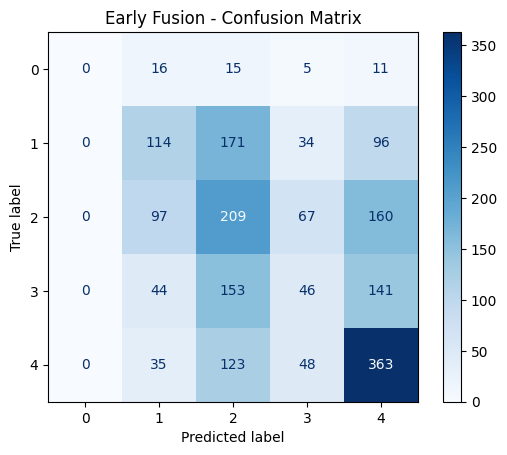

In [106]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Early Fusion
cm_early = confusion_matrix(
    y_test,
    early_test_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_early,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(cmap="Blues")
plt.title("Early Fusion - Confusion Matrix")
plt.show()

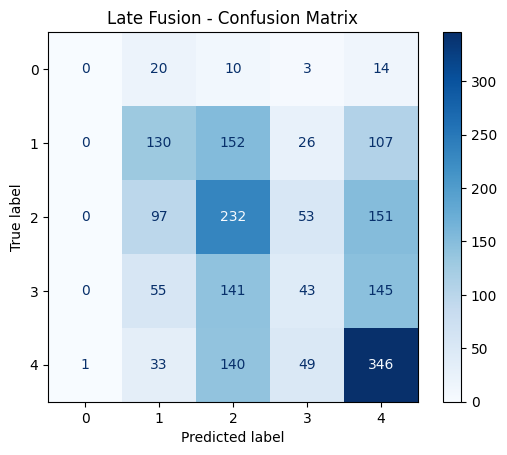

In [107]:
cm_late = confusion_matrix(
    y_test,
    late_test_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_late,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(cmap="Blues")
plt.title("Late Fusion - Confusion Matrix")
plt.show()

In [108]:
comparison = pd.DataFrame({
    "Model": [
        "Image-only",
        "Text-only",
        "Tabular-only",
        "Early Fusion",
        "Late Fusion"
    ],

    "Train Macro F1": [
        0.9785,
        0.9650,
        0.5017,
        0.9937,
        0.6880
    ],

    "Validation Macro F1": [
        0.2602,
        0.2228,
        0.2861,
        0.2974,
        0.2889
    ],

    "Test Macro F1": [
        0.2531,
        0.2106,
        0.2780,
        0.2725,
        0.2809
    ]
})

display(comparison)

,Model,Train Macro F1,Validation Macro F1,Test Macro F1
0,Image-only,0.9785,0.2602,0.2531
1,Text-only,0.9650,0.2228,0.2106
2,Tabular-only,0.5017,0.2861,0.2780
3,Early Fusion,0.9937,0.2974,0.2725
4,Late Fusion,0.6880,0.2889,0.2809


In [110]:
results_summary = pd.DataFrame({
    "Model": [
        "Image-only",
        "Text-only",
        "Tabular-only",
        "Early Fusion",
        "Late Fusion"
    ],

    "Validation Macro F1": [
        0.2602,
        0.2228,
        0.2861,
        0.2974,
        0.2889
    ],

    "Test Macro F1": [
        0.2531,
        0.2106,
        0.2780,
        0.2725,
        0.2809
    ],

    "Test Weighted F1": [
        0.3246,
        0.2749,
        0.3557,
        0.3517,
        0.3611
    ],

    "Test QWK": [
        0.2538,
        0.0920,
        0.3002,
        0.3289,
        0.3139
    ]
})

display(results_summary)

,Model,Validation Macro F1,Test Macro F1,Test Weighted F1,Test QWK
0,Image-only,0.2602,0.2531,0.3246,0.2538
1,Text-only,0.2228,0.2106,0.2749,0.0920
2,Tabular-only,0.2861,0.2780,0.3557,0.3002
3,Early Fusion,0.2974,0.2725,0.3517,0.3289
4,Late Fusion,0.2889,0.2809,0.3611,0.3139
